<p style="text-align:center"><img src="../../../Images/Banner/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Spatial SQL: DuckDB, GeoPackage and PostGIS

SQL is the language of databases, and every major cloud data platform speaks a spatial dialect
of it: PostGIS, DuckDB, BigQuery, Snowflake, Databricks and Apache Sedona all offer functions
such as `ST_Intersects`, `ST_Area` and `ST_Union`. Spatial SQL lets you join, aggregate and
filter millions of features close to where the data are stored, then hand a small result to
Python. This notebook teaches spatial SQL on real Bangladesh data with **DuckDB**, an in-process
database that needs no server, queries files directly and runs inside a notebook or a cloud
function. It then shows that a GeoPackage is a SQLite database you can query, and how the same
queries move to **PostGIS**, the standard spatial database for web GIS servers.



### Learning objectives

1. Load shapefiles, CSV tables and GeoParquet into DuckDB and inspect geometry columns.
2. Use the core spatial functions: validity, area, length, centroid, buffer, transform and union.
3. Write attribute joins, spatial joins, dissolves and window functions, and check join quality.
4. Understand when spatial indexes help, and avoid the coordinate-axis trap of `ST_Transform`.
5. Move results to GeoPandas and export them as GeoParquet, GeoPackage or FlatGeobuf.
6. Query a GeoPackage with SQL through GDAL, and translate queries to PostGIS and cloud warehouses.



### Data

| Data | Source |
|---|---|
| Upazila (sub-district, admin level 3) and union (admin level 4) boundaries of Bangladesh | `Data/00_shared/vector_data/Bangladesh/Shapefiles/bd_upzila_GCS.shp`, `bd_union_GCS.shp` |
| Upazila poverty rates, keyed by upazila code | `Data/00_shared/vector_data/Bangladesh/bd_poverty.csv` |
| Upazila population and poverty indicators, keyed by names | `Data/00_shared/vector_data/Bangladesh/bd_upazila_indicators.csv` |
| District rice production 2018-2019 (Aus, Aman and Boro seasons, metric tons) | `Data/00_shared/vector_data/Bangladesh/bd_district_rice_production_2018_2019_BTM.shp` |
| Arsenic in irrigation water, soil and rice grain at 263 rice fields in south-western Bangladesh | `Data/00_shared/vector_data/Bangladesh/bd_arsenic_data.csv` |



### Contents

1. Setup
2. Spatial databases and engines
3. Loading data into DuckDB
4. Spatial functions and the axis-order trap
5. Attribute joins and join quality
6. Dissolve and aggregate: from upazilas to districts
7. Spatial joins: arsenic in rice fields
8. Distance queries and window functions
9. Spatial indexes: when they help
10. From SQL to GeoPandas and to files
11. A GeoPackage is a SQLite database
12. PostGIS and cloud warehouses
13. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: imports, paths, output folder, and an in-memory DuckDB with the spatial extension
%matplotlib inline
import os
import shutil
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)

import duckdb
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import geolattice
import geolattice.web as web
from geolattice.vector import read_geoparquet, write_geoparquet

plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
BD = DATA / "00_shared" / "vector_data" / "Bangladesh"
OUT = DATA / "00_shared" / "data_web_cloud_gis" / "08_03_outputs"
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir(parents=True)

# Connect and load DuckDB spatial; helpers return pandas / GeoDataFrames
con = duckdb.connect()                                   # an in-memory database
con.sql("INSTALL spatial; LOAD spatial; SET enable_progress_bar = false;")
print("geolattice", geolattice.__version__, "| DuckDB", duckdb.__version__,
      "| spatial functions:", con.sql("SELECT count(DISTINCT function_name) FROM duckdb_functions() WHERE function_name LIKE 'ST_%'").fetchone()[0])

def q(sql):
    "Run SQL and return a pandas DataFrame."
    return con.sql(sql).df()

def to_gdf(sql, geom="geom", crs=4326):
    "Run SQL whose result has a geometry column and return a GeoDataFrame (geometry travels as WKB)."
    df = con.sql(f"SELECT * EXCLUDE ({geom}), ST_AsWKB({geom}) AS __wkb FROM ({sql})").df()
    geometry = gpd.GeoSeries.from_wkb(df.pop("__wkb").map(bytes), crs=crs)
    return gpd.GeoDataFrame(df, geometry=geometry.values, crs=crs).rename_geometry(geom)


geolattice 0.3.11 | DuckDB 1.5.5 | spatial functions: 158


## Spatial databases and engines

| Engine | Runs as | Best for | Spatial functions |
|---|---|---|---|
| **DuckDB** + `spatial` | A library inside your program; no server | Analysis of files (Parquet, GeoParquet, shapefiles, CSV) locally or over HTTP/S3 | ~150 `ST_` functions (GEOS, PROJ, GDAL) |
| **PostgreSQL + PostGIS** | A database server | Multi-user web GIS back ends, transactions, OGC API and tile servers | The reference implementation, several hundred functions |
| **SQLite + SpatiaLite / GeoPackage** | A file | Desktop and mobile, single-user editing | SpatiaLite functions; GeoPackage R-tree |
| **BigQuery, Snowflake, Redshift** | Cloud data warehouses | Very large tables, pay per query | `ST_` functions on GEOGRAPHY types |
| **Databricks / Apache Sedona, Spark** | Clusters | Distributed processing of billions of features | `ST_` functions on Spark DataFrames |

They share the SQL/MM spatial vocabulary, so most queries move between them with small changes
(Section 12). DuckDB needs nothing installed beyond `pip install duckdb`, which is why we learn the
patterns with it.

## Loading data into DuckDB

`ST_Read` reads any GDAL vector format into a table with a `geom` column; `read_csv` reads plain
tables. Tables live in memory unless you connect to a database file.

In [2]:
# Load Bangladesh shapefiles and CSVs into DuckDB tables (points built with ST_Point)
SHP = BD / "Shapefiles"
t0 = time.perf_counter()
con.sql(f"CREATE TABLE upazila AS SELECT * FROM ST_Read('{(SHP / 'bd_upzila_GCS.shp').as_posix()}')")
con.sql(f"CREATE TABLE unions  AS SELECT * FROM ST_Read('{(SHP / 'bd_union_GCS.shp').as_posix()}')")
con.sql(f"CREATE TABLE poverty AS SELECT * FROM read_csv('{(BD / 'bd_poverty.csv').as_posix()}')")
con.sql(f"CREATE TABLE indicators AS SELECT * FROM read_csv('{(BD / 'bd_upazila_indicators.csv').as_posix()}')")
con.sql(f'''CREATE TABLE rice AS
    SELECT ADM2_PCODE, ADM2_EN, ADM1_EN, Aus, Aman, Boro
    FROM ST_Read('{(BD / "bd_district_rice_production_2018_2019_BTM.shp").as_posix()}')''')
con.sql(f'''CREATE TABLE fields AS
    SELECT ID, WAs AS water_as, SAs AS soil_as, GAs AS grain_as, Variety AS variety, Land_type AS land_type,
           ST_Point(Longitude, Latitude) AS geom
    FROM read_csv('{(BD / 'bd_arsenic_data.csv').as_posix()}')''')
print(f"Loaded in {time.perf_counter() - t0:.2f} s")
q('''SELECT table_name, estimated_size AS rows, column_count AS columns FROM duckdb_tables() ORDER BY table_name''')


Loaded in 0.55 s


,table_name,rows,columns
0,fields,263,7
1,indicators,545,127
2,poverty,544,2
3,rice,64,6
4,unions,5160,20
5,upazila,544,18


In [3]:
# Inspect selected columns and types from the upazila table
q("DESCRIBE upazila").iloc[[0, 2, 6, 8, 10, -1]][["column_name", "column_type"]]


,column_name,column_type
0,OGC_FID,BIGINT
2,Shape_Area,DOUBLE
6,ADM3ALT1EN,VARCHAR
8,ADM2_EN,VARCHAR
10,ADM1_EN,VARCHAR
17,geom,GEOMETRY('EPSG:4326')


The geometry column is typed `GEOMETRY('EPSG:4326')`: DuckDB records the coordinate system with the
column. Upazila and union tables carry the full administrative hierarchy (`ADM1` division, `ADM2`
district, `ADM3` upazila, `ADM4` union), with names (`_EN`) and codes (`_PCODE`).

## Spatial functions and the axis-order trap

A first query uses several functions at once: validity, geometry type, vertex count, area on the
ellipsoid and the centroid.

In [4]:
# Geometry summary: type, validity, area, and centroid for the largest upazilas
q('''
SELECT ADM3_EN AS upazila, ADM2_EN AS district, ST_GeometryType(geom) AS type, ST_IsValid(geom) AS valid,
       ST_NPoints(geom) AS vertices,
       round(ST_Area_Spheroid(ST_FlipCoordinates(geom)) / 1e6, 1) AS area_km2,
       round(ST_X(ST_Centroid(geom)), 4) AS lon, round(ST_Y(ST_Centroid(geom)), 4) AS lat
FROM upazila
ORDER BY area_km2 DESC
LIMIT 5''')


,upazila,district,type,valid,vertices,area_km2,lon,lat
0,Baghai Chhari,Rangamati,POLYGON,True,2589,1616.1,92.2295,23.3731
1,Shyamnagar,Satkhira,MULTIPOLYGON,True,11191,1544.4,89.1793,22.0690
2,Mongla,Bagerhat,MULTIPOLYGON,True,11867,1268.5,89.6544,22.1271
3,Koyra,Khulna,MULTIPOLYGON,True,10123,1255.2,89.3822,22.1455
4,Thanchi,Bandarban,POLYGON,True,1702,1078.9,92.5309,21.6373


For metric work (buffers, distances, areas) data are usually projected. Here is the trap:
**EPSG:4326 officially lists latitude first**. DuckDB's `ST_Transform` follows the official axis
order unless told otherwise, so a point stored as (longitude, latitude) is read the wrong way round.

In [5]:
# Compare ST_Transform axis order with and without always_xy := true
q('''
SELECT ST_AsText(ST_Transform(ST_Point(90.40, 23.81), 'EPSG:4326', 'EPSG:32646'))                       AS default_order,
       ST_AsText(ST_Transform(ST_Point(90.40, 23.81), 'EPSG:4326', 'EPSG:32646', always_xy := true))   AS always_xy,
       ST_AsText(ST_Transform(ST_Point(23.81, 90.40), 'EPSG:4326', 'EPSG:32646'))                       AS lat_lon_input''')


,default_order,always_xy,lat_lon_input
0,POINT (inf inf),POINT (235102.69622060267 2635618.6821711794),POINT (235102.69622060267 2635618.6821711794)


The first column is the trap: transforming `ST_Point(90.40, 23.81)` from EPSG:4326 with the
default settings gives `POINT (inf inf)`, because DuckDB read 90.40 as a latitude, which is
impossible. Supplying the coordinates as (latitude, longitude), or adding `always_xy := true`, gives
the correct UTM position (about 235 km east, 2,636 km north). Coordinates in files are almost always
stored longitude first, so use `always_xy := true` whenever the source is EPSG:4326.

The query above it also shows why projected or ellipsoidal measures matter: the largest upazilas
are in the Chittagong Hill Tracts (Baghai Chhari, 1,616 km²) and the Sundarbans coast (Shyamnagar,
Mongla, Koyra). The coastal ones are multipolygons with over 10,000 vertices each, because of their
many islands and channels.

## Attribute joins and join quality

The poverty table has one row per upazila with an upazila code (`ADM3_PCODE`), so joining it to the
upazila polygons should give a poverty map. Before trusting any join, check three numbers: how many
rows match, how many rows are left over on each side (**anti-joins**), and whether the key is unique.

In [6]:
# Check how well poverty rows join to upazila polygons on ADM3_PCODE
q('''
SELECT (SELECT count(*) FROM upazila)                                            AS polygons,
       (SELECT count(*) FROM poverty)                                            AS poverty_rows,
       (SELECT count(DISTINCT ADM3_PCODE) FROM poverty)                          AS distinct_codes_in_table,
       (SELECT count(*) FROM upazila u JOIN poverty p USING (ADM3_PCODE))        AS joined_rows,
       (SELECT count(*) FROM upazila u ANTI JOIN poverty p USING (ADM3_PCODE))   AS polygons_without_data''')


,polygons,poverty_rows,distinct_codes_in_table,joined_rows,polygons_without_data
0,544,544,525,544,19


In [7]:
# Find ADM3_PCODE values that appear with more than one upazila name in bd_data
con.sql(f"CREATE TABLE bd_data AS SELECT * FROM read_csv('{(BD / 'bd_data.csv').as_posix()}')")
q('''
SELECT p.ADM3_PCODE, count(*) AS rows_with_this_code,
       list(DISTINCT b.DISTRICT_NAME || ' / ' || b.UPAZILA_NAME) AS upazilas_in_table,
       list(DISTINCT p.POVERTY_PERCENT) AS poverty_values,
       any_value(u.ADM2_EN || ' / ' || u.ADM3_EN) AS polygon_with_this_code
FROM poverty p
JOIN bd_data b USING (ADM3_PCODE, POVERTY_PERCENT)
JOIN upazila u USING (ADM3_PCODE)
GROUP BY p.ADM3_PCODE HAVING count(*) > 1
ORDER BY rows_with_this_code DESC LIMIT 6''')


,ADM3_PCODE,rows_with_this_code,upazilas_in_table,poverty_values,polygon_with_this_code
0,BD303334,4,"[Jhenaidah / Kaliganj, Satkhira / Kaliganj, La...","[48.0, 35.3, 24.0, 15.7]",Gazipur / Kaliganj
1,BD305610,3,"[Khulna / Daulatpur, Manikganj / Daulatpur, Ku...","[29.4, 34.5, 4.0]",Manikganj / Daulatpur
2,BD457218,2,"[Netrakona / Durgapur, Rajshahi / Durgapur]","[25.7, 30.2]",Netrakona / Durgapur
3,BD201547,2,"[Chittagong / Lohagara, Narail / Lohagara]","[18.3, 19.9]",Chittagong / Lohagara
4,BD558576,2,"[Rangpur / Pirganj, Thakurgaon / Pirganj]","[23.3, 46.9]",Rangpur / Pirganj
5,BD302662,2,"[Dhaka / Nawabganj, Dinajpur / Nawabganj]","[37.3, 21.1]",Dhaka / Nawabganj


The numbers do not add up. 544 rows joined, yet 19 polygons got no data, and the table has only
**525 distinct codes for 544 rows**. Sixteen codes are repeated, and the repeats carry different
poverty values: `BD303334` appears four times (15.7, 24.0, 35.3 and 48.0%), once for each upazila
called *Kaliganj* in four districts.

Whoever built the table assigned codes by upazila **name**, so upazilas sharing a name received the
same code. A plain join therefore attaches four different poverty rates to Gazipur's Kaliganj and
none to the other three. Here the row count looked right, which makes this the most dangerous kind
of join error. Checking `count(DISTINCT key)` catches it.

The fix is a key that really identifies an upazila: the **district code plus the upazila name**.
`bd_data.csv` holds the same poverty values with district codes and names. Names still differ in
spelling, so we join in three steps and record how each row was matched:

1. exact match on district code and lower-case name;
2. fuzzy match for the rest: same district (by code, or by a near-identical district name), names
   normalised (spaces, punctuation, "Upazila" and bracketed parts removed), best Jaro-Winkler
   similarity of at least 0.9;
3. a small manual lookup for names that changed, which no string similarity can find.

In [8]:
# Build poverty_clean: exact name match, then fuzzy match, then a few manual fixes
con.sql(r'''CREATE MACRO norm(s) AS
    regexp_replace(regexp_replace(lower(trim(s)), '\s*upazila$|\s*\(.*\)', '', 'g'), '[^a-z]', '', 'g')''')
con.sql("CREATE TABLE manual_names (district VARCHAR, upazila VARCHAR, table_district VARCHAR, table_upazila VARCHAR, reason VARCHAR)")
con.sql('''INSERT INTO manual_names VALUES
    ('Jessore',   'Kotwali',         'Jessore',          'Jessore Sadar',          'Kotwali is the Jessore Sadar upazila'),
    ('Nawabganj', 'Nawabganj Sadar', 'Chapai Nababganj', 'Chapai Nababganj Sadar', 'Nawabganj district was renamed Chapai Nawabganj')''')
con.sql('''
CREATE TABLE poverty_clean AS
WITH exact AS (
    SELECT u.ADM3_PCODE, b.POVERTY_PERCENT AS poverty, 'exact' AS matched_by
    FROM upazila u JOIN bd_data b ON u.ADM2_PCODE = b.DISTRICT_PCODE AND lower(trim(u.ADM3_EN)) = lower(trim(b.UPAZILA_NAME))),
rest_u AS (SELECT * FROM upazila WHERE ADM3_PCODE NOT IN (SELECT ADM3_PCODE FROM exact)),
rest_b AS (SELECT * FROM bd_data b WHERE NOT EXISTS (
    SELECT 1 FROM upazila u WHERE u.ADM2_PCODE = b.DISTRICT_PCODE AND lower(trim(u.ADM3_EN)) = lower(trim(b.UPAZILA_NAME)))),
fuzzy AS (
    SELECT ADM3_PCODE, poverty, 'fuzzy' AS matched_by FROM (
        SELECT u.ADM3_PCODE, b.POVERTY_PERCENT AS poverty,
               jaro_winkler_similarity(norm(u.ADM3_EN), norm(b.UPAZILA_NAME)) AS sim,
               row_number() OVER (PARTITION BY u.ADM3_PCODE
                                  ORDER BY jaro_winkler_similarity(norm(u.ADM3_EN), norm(b.UPAZILA_NAME)) DESC) AS r
        FROM rest_u u JOIN rest_b b
          ON u.ADM2_PCODE = b.DISTRICT_PCODE OR jaro_winkler_similarity(norm(u.ADM2_EN), norm(b.DISTRICT_NAME)) > 0.9)
    WHERE r = 1 AND sim >= 0.9),
manual AS (
    SELECT u.ADM3_PCODE, b.POVERTY_PERCENT AS poverty, 'manual' AS matched_by
    FROM manual_names m
    JOIN upazila u ON u.ADM2_EN = m.district AND u.ADM3_EN = m.upazila
    JOIN bd_data b ON b.DISTRICT_NAME = m.table_district AND b.UPAZILA_NAME = m.table_upazila)
SELECT * FROM exact UNION ALL SELECT * FROM fuzzy UNION ALL SELECT * FROM manual''')
q('''SELECT matched_by, count(*) AS upazilas FROM poverty_clean GROUP BY 1
     UNION ALL SELECT 'total distinct codes', count(DISTINCT ADM3_PCODE) FROM poverty_clean
     UNION ALL SELECT 'polygons still without data', (SELECT count(*) FROM upazila u ANTI JOIN poverty_clean USING (ADM3_PCODE))''')


,matched_by,upazilas
0,exact,521
1,manual,2
2,fuzzy,21
3,total distinct codes,544
4,polygons still without data,0


Population comes from a third table keyed only by upper-case district and upazila names; the same
normalise-then-fuzzy approach links it.

In [9]:
# Fuzzy-match population from the indicators table onto upazila polygons by name
con.sql('''
CREATE TABLE pop_clean AS
SELECT ADM3_PCODE, population, sim FROM (
    SELECT u.ADM3_PCODE, i."Total Population (N)" AS population,
           jaro_winkler_similarity(norm(u.ADM3_EN), norm(i."Upazila Name")) AS sim,
           row_number() OVER (PARTITION BY u.ADM3_PCODE
                              ORDER BY jaro_winkler_similarity(norm(u.ADM3_EN), norm(i."Upazila Name")) DESC) AS r
    FROM upazila u JOIN indicators i ON jaro_winkler_similarity(norm(u.ADM2_EN), norm(i."Zila Name")) > 0.9)
WHERE r = 1 AND sim >= 0.9''')
q('''SELECT count(*) AS upazilas_with_population, count(*) FILTER (WHERE sim < 1) AS fuzzy_matches,
            (SELECT count(*) FROM upazila) - count(*) AS without_population,
            sum(population) AS total_population FROM pop_clean''')


,upazilas_with_population,fuzzy_matches,without_population,total_population
0,538,3,6,141730060.0


The three-step join links every upazila exactly once:

* **521 exact** matches on district code and name;
* **21 fuzzy** matches. Most are spelling variants ("Daulatkhan" / "Daulat Khan", "Tungi Para" /
  "Tungipara"); nine are all upazilas of one district, spelled "Brahamanbaria" in the shapefile and
  "Brahmanbaria", with a different district code, in the table;
* **2 manual** matches for places whose names changed. No string similarity links "Kotwali" to
  "Jessore Sadar", or "Nawabganj" to "Chapai Nababganj".

The population table matched 538 upazilas (3 fuzzy). The 6 without population drop out of the
population weights in the next section.

The original code-only join was not just incomplete but wrong. It also inflates aggregates: the
duplicated rows would add extra "upazilas" to districts such as Bogra, Rangpur and Netrakona
(Exercise 2).

## Dissolve and aggregate: from upazilas to districts

`ST_Union_Agg` merges the polygons of each group (a *dissolve*). Combined with `GROUP BY` and the
joined tables we build district statistics in one query: area, population, population-weighted
poverty and rice production from the district table.

In [10]:
# Dissolve upazilas to districts, then join rice production into district_stats
t0 = time.perf_counter()
con.sql('''
CREATE TABLE districts AS
WITH u AS (
    SELECT z.ADM1_EN, z.ADM2_EN, z.ADM2_PCODE, z.geom, pv.poverty, p.population
    FROM upazila z
    LEFT JOIN poverty_clean pv USING (ADM3_PCODE)
    LEFT JOIN pop_clean p USING (ADM3_PCODE))
SELECT ADM1_EN AS division, ADM2_EN AS district, ADM2_PCODE,
       count(*) AS upazilas,
       ST_Union_Agg(geom) AS geom,
       CAST(sum(population) AS BIGINT) AS population,
       CAST(round(sum(poverty * population) / sum(population) FILTER (WHERE poverty IS NOT NULL), 1) AS DOUBLE) AS poverty_pct
FROM u GROUP BY ALL''')
con.sql('''
CREATE TABLE district_stats AS
SELECT d.*, CAST(round(ST_Area_Spheroid(ST_FlipCoordinates(d.geom)) / 1e6) AS DOUBLE) AS area_km2,
       CAST(r.Aus + r.Aman + r.Boro AS BIGINT) AS rice_t,
       CAST(round(100.0 * r.Boro / (r.Aus + r.Aman + r.Boro), 1) AS DOUBLE) AS boro_share_pct
FROM districts d LEFT JOIN rice r USING (ADM2_PCODE)''')
print(f"Dissolved 544 upazilas into {q('SELECT count(*) n FROM districts').n[0]} districts in {time.perf_counter() - t0:.1f} s")
q('''SELECT division, district, upazilas, area_km2, population, poverty_pct, rice_t, boro_share_pct,
            round(rice_t / area_km2) AS rice_t_per_km2
     FROM district_stats ORDER BY rice_t DESC LIMIT 8''')


Dissolved 544 upazilas into 64 districts in 1.0 s


,division,district,upazilas,area_km2,population,poverty_pct,rice_t,boro_share_pct,rice_t_per_km2
0,Mymensingh,Mymensingh,12,4348.0,5118180,50.4,1708590,59.6,393.0
1,Rangpur,Dinajpur,13,3460.0,2986280,37.9,1472046,46.3,425.0
2,Rajshahi,Naogaon,11,3444.0,2592160,16.9,1439751,56.7,418.0
3,Rajshahi,Bogra,12,2913.0,3410260,16.6,1234994,57.5,424.0
4,Chittagong,Comilla,16,3088.0,5390960,37.8,1169503,56.6,379.0
5,Khulna,Jessore,8,2585.0,2042760,40.3,1163351,64.4,450.0
6,Rangpur,Rangpur,8,2344.0,2721100,45.9,1141918,53.0,487.0
7,Mymensingh,Netrakona,10,2804.0,2226800,35.3,1017099,71.0,363.0


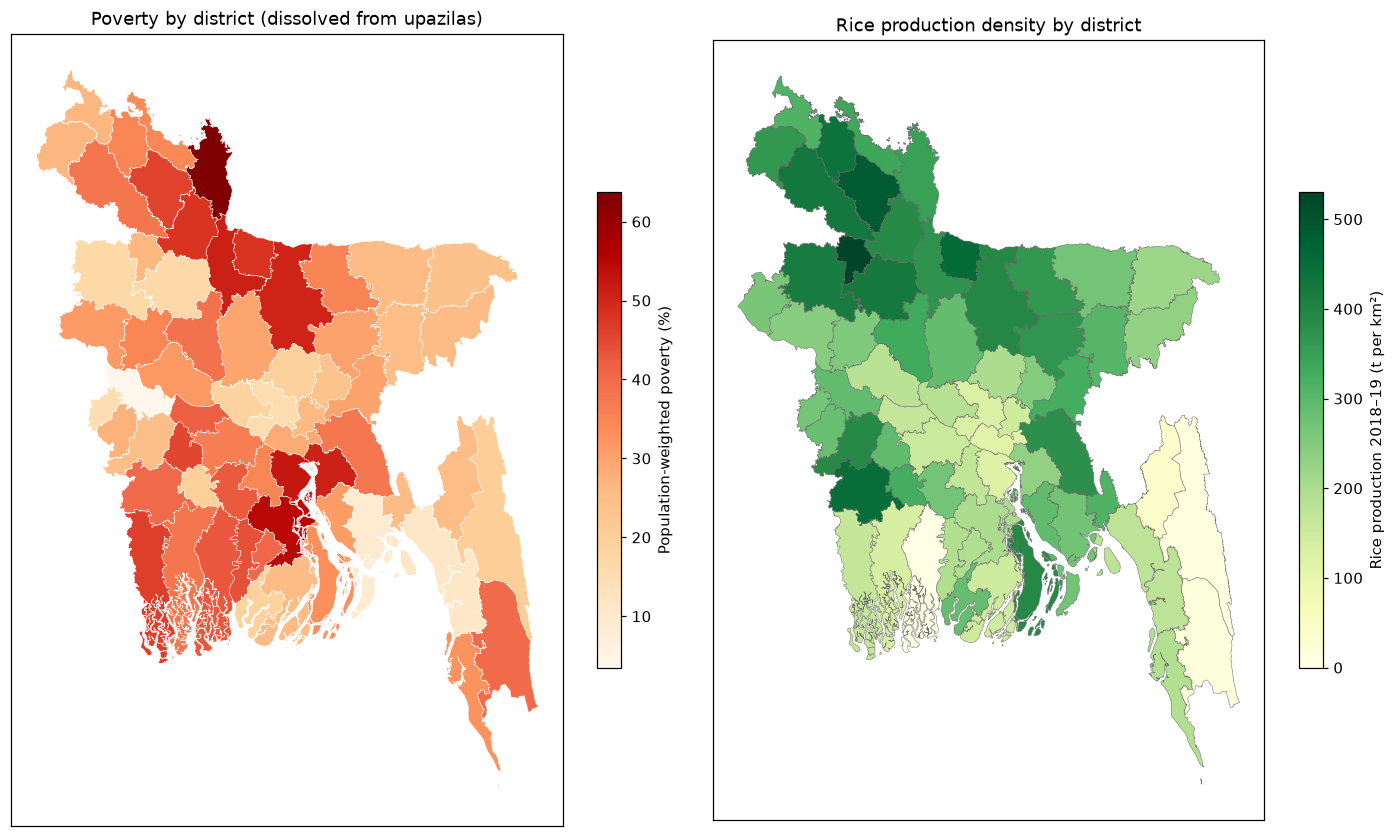

In [11]:
# Map district poverty and rice production density side by side
dist = to_gdf("SELECT district, division, poverty_pct, rice_t, area_km2, geom FROM district_stats")
fig, axes = plt.subplots(1, 2, figsize=(13, 7.5))
dist.plot(column="poverty_pct", cmap="OrRd", legend=True, ax=axes[0], edgecolor="w", lw=0.3,
          legend_kwds={"label": "Population-weighted poverty (%)", "shrink": 0.6})
axes[0].set_title("Poverty by district (dissolved from upazilas)")
dist.assign(density=dist.rice_t / dist.area_km2).plot(column="density", cmap="YlGn", legend=True, ax=axes[1],
          edgecolor="0.4", lw=0.3, legend_kwds={"label": "Rice production 2018-19 (t per km²)", "shrink": 0.6})
axes[1].set_title("Rice production density by district")
for a in axes:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()


One query dissolved 544 upazilas into 64 district polygons in about a second, and attached
population, population-weighted poverty and rice production. The largest producer was Mymensingh
(1.71 million t in 2018-19), followed by Dinajpur and Naogaon. Boro, the irrigated dry-season crop,
made up 46-71% of production in these leading districts. Production density ranges from close to zero
in the Chittagong Hill Tracts to about 500 t per km² in the north-west.

The poverty map shows the familiar geography: highest in the far north (Kurigram) and along the
Padma-Meghna river belt, lowest around Dhaka and in the central-west.

## Spatial joins: arsenic in rice fields

A **spatial join** matches rows by geometry instead of by key. Each of the 263 sampled rice fields
is assigned to the union that contains it, and the water, soil and grain arsenic are summarised per
union. The World Health Organization guideline for arsenic in drinking water is 0.01 mg/L and the
Bangladesh standard is 0.05 mg/L; irrigation water above these levels moves arsenic into soil and rice.

In [12]:
# Count arsenic sample fields that fall inside a union polygon (ST_Within)
q('''
SELECT count(*) AS fields,
       count(u.ADM4_EN) AS inside_a_union,
       count(DISTINCT u.ADM4_PCODE) AS unions,
       count(DISTINCT u.ADM3_EN) AS upazilas,
       string_agg(DISTINCT u.ADM3_EN, ', ') AS upazila_names,
       string_agg(DISTINCT u.ADM2_EN, ', ') AS districts
FROM fields f LEFT JOIN unions u ON ST_Within(f.geom, u.geom)''')


,fields,inside_a_union,unions,upazilas,upazila_names,districts
0,263,263,12,1,Tala,Satkhira


In [13]:
# Aggregate water, soil, and grain arsenic by the union that contains each field
by_union = q('''
SELECT u.ADM4_EN AS union_name, u.ADM3_EN AS upazila, count(*) AS fields,
       round(avg(f.water_as), 3) AS water_as_mean,
       round(100.0 * avg(CASE WHEN f.water_as > 0.05 THEN 1 ELSE 0 END), 0) AS pct_above_bd_standard,
       round(100.0 * avg(CASE WHEN f.water_as > 0.01 THEN 1 ELSE 0 END), 0) AS pct_above_who,
       round(avg(f.soil_as), 1) AS soil_as_mean, round(avg(f.grain_as), 3) AS grain_as_mean
FROM fields f JOIN unions u ON ST_Within(f.geom, u.geom)
GROUP BY ALL ORDER BY water_as_mean DESC''')
by_union


,union_name,upazila,fields,water_as_mean,pct_above_bd_standard,pct_above_who,soil_as_mean,grain_as_mean
0,Magura,Tala,16,0.198,100.0,100.0,18.3,0.377
1,Khesra,Tala,20,0.172,100.0,100.0,16.8,0.355
2,Islamkati,Tala,22,0.166,95.0,100.0,15.1,0.298
3,Kumira,Tala,15,0.164,100.0,100.0,13.1,0.360
4,Jalalpur,Tala,13,0.153,77.0,100.0,20.2,0.333
5,Khalishkhali,Tala,25,0.150,100.0,100.0,21.2,0.335
6,Sarulia,Tala,36,0.136,94.0,100.0,20.6,0.311
7,Dhandia,Tala,19,0.128,79.0,100.0,17.0,0.318
8,Khalilnagar,Tala,17,0.123,82.0,100.0,16.2,0.358
9,Nagarghata,Tala,40,0.091,90.0,100.0,23.2,0.355


Correlations between arsenic in water, soil and grain: {'water_soil': 0.24, 'soil_grain': 0.29, 'water_grain': 0.33}


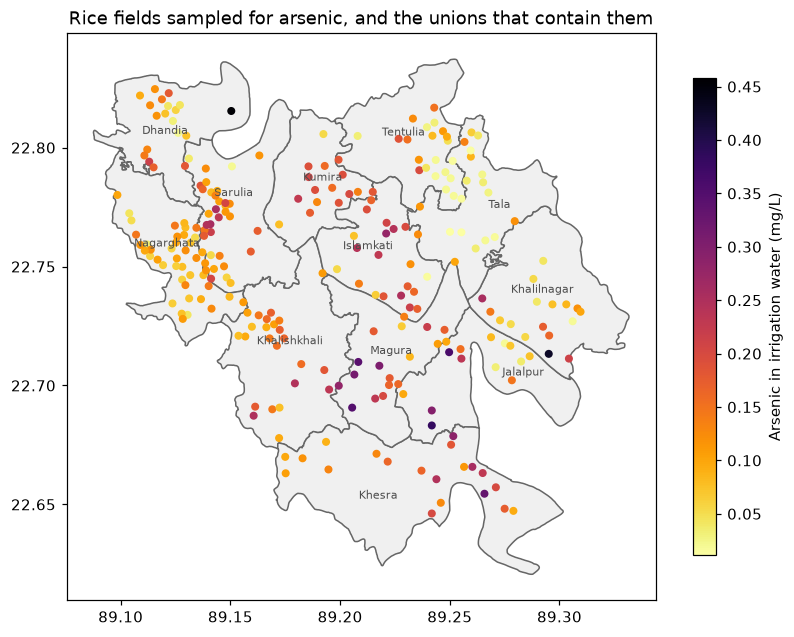

In [14]:
# Correlate arsenic measures and map sample points over the unions that contain them
corr = q("SELECT corr(water_as, soil_as) AS water_soil, corr(soil_as, grain_as) AS soil_grain, corr(water_as, grain_as) AS water_grain FROM fields")
print("Correlations between arsenic in water, soil and grain:", corr.round(2).to_dict("records")[0])
pts = to_gdf("SELECT ID, water_as, soil_as, grain_as, geom FROM fields")
area = to_gdf('''SELECT DISTINCT u.ADM4_EN, u.geom FROM unions u JOIN fields f ON ST_Within(f.geom, u.geom)''')
fig, ax = plt.subplots(figsize=(7.5, 6.5))
area.plot(ax=ax, color="#f0f0f0", edgecolor="0.4")
for _, r in area.iterrows():
    c = r.geom.representative_point()
    ax.annotate(r.ADM4_EN, (c.x, c.y), fontsize=7, ha="center", color="0.3")
pts.plot(ax=ax, column="water_as", cmap="inferno_r", markersize=18, legend=True,
         legend_kwds={"label": "Arsenic in irrigation water (mg/L)", "shrink": 0.7})
ax.set_title("Rice fields sampled for arsenic, and the unions that contain them")
plt.tight_layout(); plt.show()


All 263 fields fall inside a union: 12 unions of **Tala upazila, Satkhira district**, in the
south-west. Arsenic in the irrigation water is high everywhere:

* the union means range from 0.051 mg/L (Tala union) to 0.198 mg/L (Magura union);
* in every union except Tala itself, at least 45% of fields exceed the Bangladesh drinking-water
  standard of 0.05 mg/L;
* every union has fields above the WHO guideline of 0.01 mg/L.

The highest values are in the southern unions (Magura, Khesra, Islamkati). Correlations among water,
soil and grain arsenic are positive but weak (0.24-0.33). Grain arsenic depends on more than
irrigation water: soil chemistry, rice variety and water management all play a part.

## Distance queries and window functions

Distances need a projected coordinate system (metres). We project to UTM zone 46N (with
`always_xy := true`) and ask: how many unions lie within 5 km of at least one sampled field? Then a
**window function** ranks upazilas by poverty within each division, a task that would need a loop in
plain Python.

In [15]:
# Count unions within 5 km of any field after projecting both layers to UTM 46N
q('''
WITH f AS (SELECT ST_Transform(geom, 'EPSG:4326', 'EPSG:32646', always_xy := true) AS g FROM fields),
     u AS (SELECT ADM4_EN, ADM3_EN, ST_Transform(geom, 'EPSG:4326', 'EPSG:32646', always_xy := true) AS g
           FROM unions WHERE ST_Intersects(geom, (SELECT ST_Buffer(ST_Envelope(ST_Collect(list(geom))), 0.2) FROM fields)))
SELECT count(DISTINCT u.ADM4_EN) AS unions_within_5_km, count(DISTINCT u.ADM3_EN) AS upazilas,
       round(max(ST_Distance(u.g, f.g)) / 1000, 2) AS max_km_checked
FROM u JOIN f ON ST_DWithin(u.g, f.g, 5000)''')


,unions_within_5_km,upazilas,max_km_checked
0,37,7,5.0


In [16]:
# Window function: the two poorest upazilas in each division
q('''
SELECT division, rank, upazila, district, poverty_pct
FROM (
    SELECT z.ADM1_EN AS division, z.ADM3_EN AS upazila, z.ADM2_EN AS district, p.poverty AS poverty_pct,
           row_number() OVER (PARTITION BY z.ADM1_EN ORDER BY p.poverty DESC) AS rank
    FROM upazila z JOIN poverty_clean p USING (ADM3_PCODE))
WHERE rank <= 2 ORDER BY division, rank''')


,division,rank,upazila,district,poverty_pct
0,Barisal,1,Mehendiganj,Barisal,64.4
1,Barisal,2,Hizla,Barisal,62.3
2,Chittagong,1,Haim Char,Chandpur,61.3
3,Chittagong,2,Kachua,Chandpur,56.3
4,Dhaka,1,Gosairhat,Shariatpur,58.3
5,Dhaka,2,Bhedarganj,Shariatpur,56.3
6,Khulna,1,Mohammadpur,Magura,50.8
7,Khulna,2,Shyamnagar,Satkhira,50.2
8,Mymensingh,1,Nandail,Mymensingh,60.7
9,Mymensingh,2,Phulpur,Mymensingh,58.8


Projected to UTM, 37 unions in 7 upazilas lie within 5 km of a sampled field. The query first
restricts unions to a box around the fields so that the distance test runs on a small set.

The window function ranks upazilas inside each division in one pass. The poorest upazilas in each
division range from Rajshahi's Chauhali (45.5%) to Rangpur's Char Rajibpur (68.8%), mostly
char-land (river-island) and haor (wetland) areas.

## Spatial indexes: when they help

A spatial index (an **R-tree**) stores bounding boxes in a tree so a query can skip features far
from the area of interest. DuckDB already builds a temporary index inside a spatial join, so an
explicit index matters mostly for **repeated selective queries** against a stored table. We time
both cases on 200,000 random points.

In [17]:
# Benchmark spatial joins with and without an R-tree index on 200k random points
rng = np.random.default_rng(0)
n = 200_000
con.register("pts_df", pd.DataFrame({"lon": rng.uniform(88.0, 92.7, n), "lat": rng.uniform(20.6, 26.6, n)}))
con.sql("CREATE TABLE points AS SELECT row_number() OVER () AS id, ST_Point(lon, lat) AS geom FROM pts_df")

def timed(sql, repeat=1):
    t0 = time.perf_counter()
    for _ in range(repeat):
        result = con.sql(sql).fetchone()[0]
    return result, (time.perf_counter() - t0) / repeat

join_sql = "SELECT count(*) FROM points p JOIN unions u ON ST_Contains(u.geom, p.geom)"
window_sql = "SELECT count(*) FROM points WHERE ST_Intersects(geom, ST_MakeEnvelope(90.35, 23.70, 90.45, 23.82))"
plan = con.sql("EXPLAIN " + join_sql).fetchall()[0][1]
print("The join is planned as:", [l.strip(" │") for l in plan.split("\n") if "JOIN" in l][0])
rows = []
n_join, t_join = timed(join_sql)
n_win, t_win = timed(window_sql, repeat=20)
rows += [{"query": "points in unions (spatial join)", "index": "none", "result": n_join, "seconds": t_join},
         {"query": "points in a Dhaka box (×20, average)", "index": "none", "result": n_win, "seconds": t_win}]
# Build R-tree and repeat the same queries for a before/after timing table
t0 = time.perf_counter()
con.sql("CREATE INDEX points_rtree ON points USING RTREE (geom)")
t_build = time.perf_counter() - t0
n_join2, t_join2 = timed(join_sql)
n_win2, t_win2 = timed(window_sql, repeat=20)
rows += [{"query": "points in unions (spatial join)", "index": "R-tree on points", "result": n_join2, "seconds": t_join2},
         {"query": "points in a Dhaka box (×20, average)", "index": "R-tree on points", "result": n_win2, "seconds": t_win2}]
print(f"R-tree built in {t_build:.2f} s")
pd.DataFrame(rows).round(4)


The join is planned as: SPATIAL_JOIN


R-tree built in 0.04 s


,query,index,result,seconds
0,points in unions (spatial join),none,87647,1.3508
1,"points in a Dhaka box (×20, average)",none,69,0.0156
2,points in unions (spatial join),R-tree on points,87647,1.3370
3,"points in a Dhaka box (×20, average)",R-tree on points,69,0.0005


DuckDB planned the 200,000-point join as a `SPATIAL_JOIN`, which builds its own temporary index,
so an explicit R-tree changed nothing (about 1.35 s both ways). For the selective query, points
inside a small Dhaka box repeated 20 times, the R-tree (built in 0.04 s) made each query 25-30 times
faster (about 0.016 s down to under 0.001 s), because the index finds the 69 matching points without
scanning all 200,000.

Indexes cost time to build and space to store. They pay off for tables that are queried
repeatedly with small windows, which is typical of web services.

## From SQL to GeoPandas and to files

Results move to GeoPandas through WKB (Section 6 used the small `to_gdf` helper). DuckDB also writes
files directly with `COPY`: Parquet with GeoParquet metadata, and any GDAL format.

In [18]:
# Export district_stats to Parquet, GeoPackage, FlatGeobuf, and GeoParquet
src = "SELECT district, division, population, poverty_pct, rice_t, area_km2, geom FROM district_stats"
con.sql(f"COPY ({src}) TO '{(OUT / 'districts_duckdb.parquet').as_posix()}' (FORMAT parquet, COMPRESSION zstd)")
con.sql(f"COPY ({src}) TO '{(OUT / 'districts.gpkg').as_posix()}' WITH (FORMAT GDAL, DRIVER 'GPKG', SRS 'EPSG:4326')")
con.sql(f"COPY ({src}) TO '{(OUT / 'districts.fgb').as_posix()}' WITH (FORMAT GDAL, DRIVER 'FlatGeobuf', SRS 'EPSG:4326')")
write_geoparquet(OUT / "districts_geolattice.parquet", dist.merge(q("SELECT district, population FROM district_stats"), on="district"))
rows = []
for name in ["districts_duckdb.parquet", "districts_geolattice.parquet"]:
    i = web.geoparquet_info(OUT / name)
    rows.append({"file": name, "GeoParquet version": i["version"], "bbox covering": i["covering"],
                 "CRS": i["crs"].to_string() if i["crs"] is not None else None, "rows": i["num_rows"],
                 "KB": round((OUT / name).stat().st_size / 1e3)})
display(pd.DataFrame(rows))
print("GeoPackage and FlatGeobuf read back:", len(gpd.read_file(OUT / "districts.gpkg")), len(gpd.read_file(OUT / "districts.fgb")))


,file,GeoParquet version,bbox covering,CRS,rows,KB
0,districts_duckdb.parquet,1.0.0,False,EPSG:4326,64,14664
1,districts_geolattice.parquet,1.1.0,True,EPSG:4326,64,14888


GeoPackage and FlatGeobuf read back: 64 64


DuckDB's `COPY ... (FORMAT parquet)` writes valid GeoParquet, but version 1.0 without a bbox
covering column. `write_geoparquet` writes version 1.1 with the covering column and spatially
sorted rows, which matter for remote filtering (Notebook 08_02). Through GDAL, `COPY` also wrote a
GeoPackage and a FlatGeobuf that GeoPandas read back (64 districts each).

Large integer sums become 38-digit DECIMAL values in DuckDB, which GDAL cannot store. This is why
the district query casts population and production to `BIGINT`.

## A GeoPackage is a SQLite database

A GeoPackage file is an SQLite database with standard tables for metadata and an R-tree spatial
index per layer. GDAL can run SQL against it in the SQLite dialect, including spatial functions, and
the R-tree can be queried like any table.

In [19]:
# Query the GeoPackage with SQLite spatial SQL via its built-in R-tree
from osgeo import gdal, ogr
gdal.UseExceptions()
gpkg = gdal.OpenEx((OUT / "districts.gpkg").as_posix(), gdal.OF_VECTOR)
layer_name = gpkg.GetLayer(0).GetName()
print("Layer:", layer_name)
system = gpkg.ExecuteSQL("SELECT table_name, data_type FROM gpkg_contents UNION ALL "
                         "SELECT table_name, extension_name FROM gpkg_extensions", dialect="SQLite")
print([tuple(f.GetField(i) for i in range(2)) for f in system]); gpkg.ReleaseResultSet(system)

sql = f'''SELECT district, poverty_pct, ST_Area(geom) AS area_deg2
          FROM "{layer_name}"
          WHERE fid IN (SELECT id FROM "rtree_{layer_name}_geom"
                        WHERE minx <= 90.45 AND maxx >= 90.35 AND miny <= 23.82 AND maxy >= 23.70)'''
result = gpkg.ExecuteSQL(sql, dialect="SQLite")
print("Districts whose R-tree box overlaps central Dhaka:",
      [(f.GetField("district"), f.GetField("poverty_pct")) for f in result])
gpkg.ReleaseResultSet(result); gpkg = None


Layer: districts
[('districts', 'features'), ('districts', 'gpkg_rtree_index')]
Districts whose R-tree box overlaps central Dhaka: [('Narayanganj', 26.1), ('Dhaka', 15.3)]


The R-tree table (`rtree_<layer>_geom`) holds one bounding box per feature; filtering it first is
exactly what a spatial index does. The same file opens in QGIS, ArcGIS and any SQLite client.

## PostGIS and cloud warehouses

**PostGIS** extends PostgreSQL and is the usual back end of a web GIS: pygeoapi, GeoServer,
Martin and pg_tileserv serve features and vector tiles straight from it, and many users can read
and write at the same time. Data are loaded with `ogr2ogr` (or GeoPandas' `to_postgis`), and the SQL
we wrote above carries over with small changes:

| Task | DuckDB | PostGIS | BigQuery |
|---|---|---|---|
| Read a file | `ST_Read('x.shp')`, `read_parquet(...)` | load with `ogr2ogr -f PostgreSQL` | load job / external table |
| Area in m² | `ST_Area_Spheroid(ST_FlipCoordinates(g))` | `ST_Area(g::geography)` | `ST_AREA(g)` (GEOGRAPHY) |
| Dissolve | `ST_Union_Agg(g)` | `ST_Union(g)` (aggregate) | `ST_UNION_AGG(g)` |
| Reproject | `ST_Transform(g, 'EPSG:4326', 'EPSG:32646', always_xy := true)` | `ST_Transform(g, 32646)` (lon/lat order) | not needed (geodesic) |
| Spatial index | `CREATE INDEX ... USING RTREE (g)` | `CREATE INDEX ... USING GIST (g)` | automatic clustering |
| Within distance (m) | `ST_DWithin(projected, projected, 5000)` | `ST_DWithin(g::geography, h::geography, 5000)` | `ST_DWITHIN(g, h, 5000)` |

The next cell loads the district table into PostGIS with GDAL and runs the population-weighted
poverty query there, **if** a PostGIS database is available. Set the environment variable
`GEOLATTICE_POSTGIS` to a GDAL connection string such as
`PG:host=localhost dbname=gis user=gis password=...` (for example from
`docker run -e POSTGRES_PASSWORD=gis -p 5432:5432 postgis/postgis`).

In [20]:
# Optional PostGIS load via GDAL; otherwise summarize divisions in DuckDB
pg = os.environ.get("GEOLATTICE_POSTGIS")
if pg:
    gdal.VectorTranslate(pg, (OUT / "districts.gpkg").as_posix(), format="PostgreSQL",
                         layerName="bd_districts", accessMode="overwrite", layerCreationOptions=["GEOMETRY_NAME=geom"])
    ds = gdal.OpenEx(pg, gdal.OF_VECTOR)
    res = ds.ExecuteSQL('''SELECT division, round(sum(poverty_pct * population) / sum(population), 1) AS poverty_pct,
                                  round(sum(ST_Area(geom::geography)) / 1e6) AS area_km2
                           FROM bd_districts GROUP BY division ORDER BY poverty_pct DESC''')
    display(pd.DataFrame([{k: f.GetField(k) for k in ("division", "poverty_pct", "area_km2")} for f in res]))
    ds.ReleaseResultSet(res)
else:
    print("GEOLATTICE_POSTGIS is not set: the PostGIS example is skipped. The same division summary in DuckDB:")
    display(q('''SELECT division, round(sum(poverty_pct * population) / sum(population), 1) AS poverty_pct,
                        round(sum(area_km2)) AS area_km2
                 FROM district_stats GROUP BY division ORDER BY poverty_pct DESC'''))


GEOLATTICE_POSTGIS is not set: the PostGIS example is skipped. The same division summary in DuckDB:


,division,poverty_pct,area_km2
0,Mymensingh,47.2,10544.0
1,Rangpur,41.8,16287.0
2,Barisal,38.4,10141.0
3,Khulna,32.5,20750.0
4,Rajshahi,27.6,18227.0
5,Chittagong,25.9,31147.0
6,Sylhet,25.1,12373.0
7,Dhaka,24.9,20383.0


No PostGIS server was configured when this notebook was run, so the DuckDB version of the
division summary is shown. Mymensingh (47%) and Rangpur (42%) divisions have the highest
population-weighted poverty, and Dhaka (25%) the lowest. With `GEOLATTICE_POSTGIS` set, the cell loads the
GeoPackage into PostGIS with GDAL and runs the PostGIS version of the query, with `ST_Area` on
the `geography` type and `GROUP BY`.

## Summary and exercises

**Key ideas**

- Spatial SQL expresses joins, dissolves, filters and rankings declaratively, and runs them where the
  data live; DuckDB brings it to files with no server.
- Always check joins: row counts, anti-joins and key uniqueness. A duplicated key silently multiplies rows;
  name-based joins need normalisation, fuzzy matching and sometimes a manual lookup.
- `ST_Transform` from EPSG:4326 needs `always_xy := true` in DuckDB when coordinates are stored lon/lat.
- Spatial joins build their own index; explicit R-tree indexes pay off for repeated selective queries.
- GeoPackage is SQLite; PostGIS is the multi-user server; cloud warehouses speak the same `ST_` language.

**What we found**

- The upazila poverty table had duplicated codes, assigned by name, that a plain join would have
  attached to the wrong places. Rebuilding the key (district code plus name, then fuzzy and manual
  matching) linked all 544 upazilas.
- One SQL query dissolved upazilas to 64 districts with population-weighted poverty and rice production.
- All 263 arsenic-sampled rice fields lie in 12 unions of Tala upazila. Mean irrigation-water arsenic
  is 0.05-0.20 mg/L, mostly above the national standard.
- An R-tree index made a repeated window query 25-30 times faster, but did not speed up a
  spatial join, which builds its own index.

**Exercises**

1. Join `poverty_clean` to the union layer through the upazila code (`ADM3_PCODE`) and map poverty
   at union level. Why does every union in an upazila get the same value?
2. Redo the district statistics with the original `bd_poverty.csv` join (duplicated codes included).
   Which districts change most, and why?
3. Use `ST_Read` and `read_parquet` over HTTP (Notebook 08_02's `static_server` and the `httpfs`
   extension) to run the Section 7 spatial join against the remote `unions.parquet`.
4. Compute, for each division, the share of its area that lies within 10 km of a district boundary.
5. If you can run PostGIS (Docker), set `GEOLATTICE_POSTGIS`, load the union layer with `ogr2ogr`, add a
   GiST index and compare the spatial-join time with DuckDB.

**References**

- DuckDB spatial extension. https://duckdb.org/docs/extensions/spatial
- PostGIS documentation. https://postgis.net/documentation
- Obe, R. & Hsu, L. (2021). *PostGIS in Action*, 3rd ed. Manning.
- GeoPackage encoding standard (OGC 12-128r19). https://www.geopackage.org
- WHO (2022). *Guidelines for Drinking-water Quality*, 4th ed. incorporating the first and second addenda (arsenic 0.01 mg/L).